##### !pip install networkx

In [ ]:
!pip install 'scipy>=1.8'

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:


import networkx as nx
import pandas as pd
import numpy as np
from networkx.algorithms import bipartite
import operator
from operator import itemgetter, attrgetter
import pylab as plt #import Matplotlib plotting interface
import matplotlib.pyplot as plt
from datetime import datetime
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.sparse.linalg import eigs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LinearRegression

gpp = nx.Graph() #El Poder Publico
gpp1 = nx.Graph()
gpp2 = nx.Graph() #El Poder Publico JMS
gpp4 = nx.Graph() #EL Podre Publico Ivan Duque
ggaval = nx.Graph() #El Grupo Aval
godeb = nx.Graph() #Odebrecht
g = nx.Graph() #Capitulo 1: Antes del 7 de Agosto 2010 (Presidencia de AUV)
gch1 = nx.Graph() #Capitulo 1: Antes del 7 de Agosto 2010 (Presidencia de AUV)
gch2 = nx.Graph() #Capitulo 2: 7 de Agosto 2010 - 7 de Agosto 2014 (Presidencia de JMSCI)
gch3 = nx.Graph() #Capitulo 3: 7 de Agosto 2014 - 11 julio  de 2016 (Presidencia de JMSCII)
gch4 = nx.Graph() #Capitulo 4: 11 julio  de 2016 - 7 de agosto 2022 (Presidencia de JMSCII, IDM)
gch5 = nx.Graph() #Capitulo 5: 7 de Agosto 2022 (El Gobierno del cambio)
gnhmn = nx.Graph()

#EstructuraDelPoderPublico
gpp.add_edge('GNC', 'CSJ')
gpp.add_edge('GNC', 'Congreso')
gpp.add_edge('GNC', 'FGN')
gpp.add_edge('ANI', 'GNC')
gpp.add_edge('GNC','Presidencia')
gpp.add_edge('GNC','MinCo')
gpp.add_edge('Cormag','GNC') #Cormagdalena ente corporativo 
#del orden nacional con autonomía administrativa, 
#presupuestal y financiera
gpp.add_edge('ANI', 'GNC')
gpp.add_edge('ANI', 'INCO')

gpp1.add_edge('PresidenciaAUV', 'AUV')
gpp1.add_edge('AUV','MarioUribe')
gpp1.add_edge('CongresoAUV','MarioUribe')
gpp1.add_edge('PresidenciaAUV', 'Presidencia')
gpp1.add_edge('MinTransAUV', 'PresidenciaAUV')
gpp1.add_edge('GabrielGarciaM', 'MinTransAUV')#Ministro de Transporte 2006-2010


gpp2.add_edge('JMSC', 'CampanaPres2014')#) #, attr_dict = {'since': datetime(2014,5,24), 'upto': datetime(2014,7,15)})
gpp2.add_edge('RobertoPrieto', 'CampanaPres2010')
gpp2.add_edge('PresidenciaJMSC', 'CampanaPres2010')
gpp2.add_edge('MinTansJMSC', 'PresidenciaJMSC')


gpp4.add_edge('IDM', 'CampanaPres2018')
gpp4.add_edge('PresidenciaIDM', 'CampanaPres2018')



gpp2.add_edge('SuperMinJMSC', 'PresidenciaJMSC')
gpp2.add_edge('PresidenciaJMSC', 'MinCoJMSC')
gpp2.add_edge('CeciliaAlvarezCorrea', 'MinCoJMSC')
gpp2.add_edge('CeciliaAlvarezCorrea', 'GinaParody')
gpp2.add_edge('GinaParody', 'MinEdJMSC')
gpp1.add_edge('Congreso', 'PlinioOlano')
gpp2.add_edge('Congreso', 'PlinioOlano')
gpp2.add_edge('Congreso', 'MiguelElias')
gpp2.add_edge('MinTansJMSC', 'MiguelPenaloza')
gpp2.add_edge('EliasVidal', 'Congreso')
gpp1.add_edge('EliasVidal', 'MiguelElias')
gpp2.add_edge('EliasVidal', 'MiguelElias')
gpp2.add_edge('LeonidasBusatos', 'CSJ')
#estructuraDelPoderPrivado-GAVAL
ggaval.add_edge('LCSA', 'GAVAL')
ggaval.add_edge('CFC', 'GAVAL')#Adquirida 2005
ggaval.add_edge('JEliasMelo', 'CFC')#Presidente
ggaval.add_edge('GAVAL', 'NHMN')#Asesor Juridico
ggaval.add_edge('GAVAL', 'LCSG')#CEO GAVAL
ggaval.add_edge('LCSG', 'GAVAL')#Presidente
ggaval.add_edge('LCSG', 'LCSA')#Hijo
ggaval.add_edge('JGilVillegas', 'CFC')#Johanna Gil Villegas Representante legal CFC
ggaval.add_edge('CFC', 'HPalaciosMejia')#Asesor

#NHMN
#Mejorar relaciones de NCMB
gnhmn.add_edge('M&MACLtda','NHMN')
gnhmn.add_edge('NCMB','NHMN')
gnhmn.add_edge('NHMAbogados','NHMN')


#Odebrecht
godeb.add_edge('Odebrecht','ConstODB')
godeb.add_edge('EderPFerracuti', 'Odebrecht')#Exdirectivo
godeb.add_edge('EderPFerracuti', 'ConsRS')#Rep Legal Concesionaria Ruta del Sol SAS. 
godeb.add_edge('MMaragoni', 'Odebrecht')
godeb.add_edge('MMaragoni', 'Consol')#funcionario gerente del Consorcio Ruta del Sol Consol
godeb.add_edge('AHideaki', 'ConstODB')# constructora Norberto Odebrecht S.A.

#Todo elemento se registra cronologicamente según los hechos ocurridos

#####HECHOS####
#Ch1- Antes del 7 de Agosto de 2010 - Gobierno AUV

gch1.add_edge('PresidenciaAUV','RSII')#El gobierno del presidente Álvaro Uribe declara la importancia estratégica de la autopista Ruta del Sol
#Abre licitacion

gch1.add_edge('MarioUribe','Parapolitica')
gch1.add_edge('OttoB','Parapolitica')
#gch1.add_edge('AUV', 'Presidencia')#) #, attr_dict = {'since': datetime(2002,8,7), 'upto': datetime(2010,8,7) })#7 August 2002 to 7 August 2010


#22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('CSSConst', 'ConsRS')#) #, attr_dict = {'date': datetime(2009,12,22)})#4,9porciento- Constructora Norberto Odebrecht
gch1.add_edge('Odebrecht', 'ConsRS')#) #, attr_dict = {'date': datetime(2009,12,22)})#37porciento - LatinvestBest Colombia SAS
gch1.add_edge('Latinvest', 'ConsRS')#
gch1.add_edge('ConstODB', 'ConsRS')#) #, attr_dict =  {'date': datetime(2009,12,22)})#25,1porciento - 22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('Episol', 'ConsRS')#) #, attr_dict = {'date': datetime(2009,12,22)})#33 porciento - 22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('CFC', 'ConsRS')#) #, attr_dict = {'date': datetime(2009,12,22)})#33 porciento - 22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('CFC', 'Episol')#) #, attr_dict = {'date': datetime(2009,12,22)})#Filial
gch1.add_edge('ConsRS','GSolarte')
gch1.add_edge('CarlosSolarte','GSolarte')
gch1.add_edge('OttoB', 'BernardoNElias')#) #, attr_dict = {'date': datetime(2009,12,22)})
gch1.add_edge('OttoB', 'C-OG')#) #, attr_dict = {'date': datetime(2009,12,22)})
gch1.add_edge('OttoB', 'RS-SII')#) #, attr_dict = {'date': datetime(2009,12,22)})
gch1.add_edge('YesidArocha', 'Odebrecht')#) #, attr_dict = {'date': datetime(2009,12,22)})
gch1.add_edge('YesidArocha', 'OttoB')#) #, attr_dict = {'date': datetime(2009,12,22)})


gch1.add_edge('AHideaki', 'CUPanama') #consultores Unidos Panama
gch1.add_edge('MMaragoni', 'CUPanama')
gch1.add_edge('Odebrecht', 'CUPanama')

gch1.add_edge('GabrielDumar', 'SION')
gch1.add_edge('GabrielDumar', 'MMaragoni')
gch1.add_edge('RS-SII', 'SION')
gch1.add_edge('RS-SII', 'CUPanama')
gch1.add_edge('Odebrecht', 'SION')

gch1.add_edge('Odebrecht', 'TTU')#tecnica territoriales y urbanas - empresa española
gch1.add_edge('C-OG', 'TTU')
gch1.add_edge('AHideaki', 'TTU')
gch1.add_edge('FernandoPardinasPuente', 'TTU')#Representante legal
#Delito trafico de influencias --- Trascendencia de NHMN???

gch1.add_edge('Odebrecht', 'TransEqLaSabana')#Transportes y Equipos La Sabana SAS
gch1.add_edge('Odebrecht', 'AllTechCol')#AllTech Colombia SAS
gch1.add_edge('Odebrecht', 'InvCoal')#In versiones Coal SAS
gch1.add_edge('Odebrecht', 'ProfdeBolsa')

gch1.add_edge('FedeGaviria', 'TransEqLaSabana')#Transportes y Equipos La Sabana SAS
gch1.add_edge('FedeGaviria', 'AllTechCol')#AllTech Colombia SAS
gch1.add_edge('FedeGaviria', 'InvCoal')#In versiones Coal SAS
gch1.add_edge('FedeGaviria', 'ProfdeBolsa')

gch1.add_edge('OttoB', 'TransEqLaSabana')#Transportes y Equipos La Sabana SAS
gch1.add_edge('OttoB', 'AllTechCol')#AllTech Colombia SAS
gch1.add_edge('OttoB', 'InvCoal')#In versiones Coal SAS
gch1.add_edge('OttoB', 'ProfdeBolsa')

##AVpg 44
gch1.add_edge('AlbertoMariño', 'ConsRS')#Representante GAVAL en ConsRS


#Ref:
#DEBERÁ PAGAR UNA MULTA DE $144 MILLONES
#Caso Odebrecht: lo que viene después de la condena a José Elías Melo
#Judicial
#29 Abr 2019 - 10:31 PM
#Redacción Judicial
#NACIÓN (/SECCION/NACION/3) |
#12/12/2017 4:56:00 PM
#Cinco años de cárcel para el exviceministro de
#Transporte Gabriel García Morales

gch1.add_edge('RS-SII', 'GabrielGarciaM')#postestad de
gch1.add_edge('RS-SII', 'INCO(ANI)')
gch1.add_edge('GabrielGarciaM', 'INCO(ANI)')#Director INCO
gch1.add_edge('MinTransAUV', 'INCO(ANI)')
gch1.add_edge('PresidenciaAUV', 'MinTransAUV')
#JElisaMelo intermeedia pago de ConsODB a GGarciaM para aprobar contrato RS
gch1.add_edge('JEliasMelo', 'LuizBueno')#intermedió soborno a GabrielGarcia en 2009
gch1.add_edge('LuizBueno', 'Odebrecht')#intermedió soborno a GabrielGarcia en 2009
gch1.add_edge('JEliasMelo', 'GabrielGarciaM')#intermedió soborno a GabrielGarcia en 2009
gch1.add_edge('Odebrecht', 'GabrielGarciaM')#27 de octubre de 2009, cuando se
gch1.add_edge('LuizBueno', 'GabrielGarciaM')#El entonces viceministro de 
#Transporte y director encargado del Inco, Gabriel García Morales, se reúne con Luiz Bueno, 
#representante de Odebrecht en Colombia. Según García, el directivo brasilero lo amenaza 
#con denunciarlo por celebración indebida de contratos, si no se adjudica a Odebrecht el 
#tramo II de la Ruta del Sol y le ofrece una “compensación” si le garantiza que no habrá 
#intervenciones indebidas de otros proponentes en la licitación. 

gch1.add_edge('RS-SII', 'HPalaciosMejia')#Emite concepto juridico 15/12/2009
gch1.add_edge('RS-SII', 'Odebrecht')#Pago por adjudicación de 
gch1.add_edge('RS-SII', 'ConsRS')#Adjudicada a finales diciembre 2009
#reunió con los directivos de Odebrecht para negociar el "direccionamiento" del segundo
#tramo de la Ruta del Sol.


gch1.add_edge('FedeGaviria', 'OttoB')
gch1.add_edge('FedeGaviria', 'MiguelElias')
gch1.add_edge('JuanSeCorrea', 'MiguelElias')
gch1.add_edge('JuanSeCorrea', 'ANI')

gch1.add_edge('GustavoATorres', 'ProfdeBolsa')
gch1.add_edge('GustavoATorres', 'ConsRS')
gch1.add_edge('GustavoATorres', 'FedeGaviria')
gch4.add_edge('GustavoATorres', 'FGN')

gch4.add_edge('GabrielDumar', 'FGN')
gch1.add_edge('GabrielDumar', 'FedeGaviria')
gch1.add_edge('GabrielDumar', 'SION')
gch1.add_edge('ConsRS', 'SION')
gch4.add_edge('FGN', 'BernardoNElias') #, attr_dict = {'date': datetime(2017,2,24)})

gch1.add_edge('EduardoZambrano', 'CUPanama')#socio de las compañías Consultores Unidos Colombia y Consultores Unidos Panamá. 

#EL CONTRATO DE ESTABILIDAD JURÍDICA
#gch1.add_edge('M&MACLtda', 'NHMN')#Martinez & Martinez Consultores Ltda y su cabeza NHMN - AVpgch29
gch1.add_edge('M&MACLtda', 'ConsRS') #, attr_dict = {'date': datetime(2010,2,26)} ) #El 26 de Febrero de 2010 presento una propuesta para contrato de estabilidad
gch1.add_edge('M&MACLtda', 'MHarasik') #, attr_dict = {'date': datetime(2010,2,26)} )#Oferta aceptada por Marko Harasik representante lefgal de Consol
gch1.add_edge('Consol', 'MHarasik')#AV p29
gch2.add_edge('CFC', 'NHMN') #, attr_dict = {'date': datetime(2010,09)})#PODER De representacion 
gch2.add_edge('MinCo', 'NHMN')
gch2.add_edge('MHarasik', 'NHMN')
gch2.add_edge('JGilVillegas', 'NHMN')#Johanna Gil Villegas Representante legal CFC
#frente al Ministerio de Gobierno
#EL CONTRATO DE ESTABILIDAD JURIDICA
gch2.add_edge('ConsRS', 'M&MACLtda')#Poder Contrato Estabilidad Juridica Agos2010
gch2.add_edge('CFC', 'M&MACLtda')#Poder Contrato Estabilidad Juridica Agos2010
#Segun demanda de nulidad ante consejo de Estado:
gch2.add_edge('ContratoEstabilidadJuridica', 'ConsRS')
gch2.add_edge('ContratoEstabilidadJuridica','M&MACLtda')
gch2.add_edge('ContratoEstabilidadJuridica','MinCo')
gch2.add_edge('ConsRS', 'M&MACLtda')#contrato de estabilidad juridica 2012

gch3.add_edge('EstudioJuridicoMNALtda', 'ContratoEstabilidadJuridica')
#El abogado Martínez Neira formaliza la que sería su tercera asesoría a la empresa Ruta del Sol S.A.S., ofertada en esta oportunidad por otra firma suya, la sociedad Estudio Jurídico MNA Ltda, con el objeto de “resolver un requerimiento del Comité de Estabilidad Jurídica”
# sobre el acuerdo que la concesionaria había firmado con el gobierno en 2010.
gch2.add_edge('M&MACLtda', 'ConsRS', key=1)# 2012 contrato estabilidad juridica con el Ministerio de Corme


gnhmn.add_edge('EstudioJuridicoMNALtda', 'NHMN') #, attr_dict = {'date': datetime(2014,9,16)})#Constituida 16 de sept 2014
gch2.add_edge('EstudioJuridicoMNALtda', 'ConsRS') #, attr_dict = {'date': datetime(2015,7,1)})#Tercera asesoria a ConsRS
gch2.add_edge('EstudioJuridicoMNALtda', 'AlbertoMariño') 
gch2.add_edge('EstudioJuridicoMNALtda', 'INCO') 
gch2.add_edge('EstudioJuridicoMNALtda', 'OtroSi') 

gch2.add_edge('CeciliaAlvarezCorrea', 'ConsejoEstado') 
gch2.add_edge('CeciliaAlvarezCorrea', 'C-OG') 
gch2.add_edge('CeciliaAlvarezCorrea', 'RS-SII') 
gch2.add_edge('CeciliaAlvarezCorrea', 'OtroSi') 
#La ministra de Transporte Cecilia Álvarez Correa le consulta al Consejo de 
#Estado si se puede adjudicar sin licitación la vía Ocaña-Gamarra, adicionándola 
#al contrato de la Ruta del Sol mediante un otrosí. La ley es clara y el Consejo de 
#Estado se limita a recordarla, respondiéndole que no y agregando: “Las obras que no 
#guarden una relación directa y necesaria con el objeto del contrato no pueden acordarse ni ejecutarse válidamente como una adición al respectivo 
#contrato de concesión”. La construcción de dicha vía debía ser contratada “por licitación, respetando los principios de la libre concurrencia y de igualdad entre los proponentes”.



# su firma Estudio Jurídico Martínez Ltda a la concesionaria. 
#Con base en ello, la Agencia Nacional de Infraestructura, en cabeza de Luis Fernando 
#Andrade, conduce evaluaciones técnicas y económicas para fundamentar la conveniencia de la adición.
#Los empresarios Brasileros - Investigacion Fiscal Adhoc
#Titulo
#Y ahora, el turno es de los brasileros 
#7 Julio 2019 - El Espectador 
#Hechos previos a Enero 2010


gch2.add_edge('OttoB', 'AHideaki') #, attr_dict = {'date': datetime(2013,8,5)})
#Pago de 4.6 millones de dolares---Revisar fecha de hecho
gch2.add_edge('AlbertoMariño', 'NHMN') #, attr_dict = {'date': datetime(2012,8,1)})
gch2.add_edge('C-OG', 'NHMN') #, attr_dict = {'date': datetime(2012,8,1)})#Parra Moya 2018

#gch1.add_edge('RS-SII', 'SocRS')



gch2.add_edge('OttoB', 'ConstODB')#contratado por ODB 5 de Agosto 2013 - Fiscalia
gch2.add_edge('OttoB', 'C-OG')#contratado por ODB 5 de Agosto 2013
gch2.add_edge('NHMN', 'OtroSi') #, attr_dict = {'date': datetime(2014,6,1)}# 2014 concepto legal contrato Caña-Gamarra -n4

gch2.add_edge('RS-SII', 'C-OG')#ANI tramito modificacion contratoRSSII
gch2.add_edge('RS-SII', 'OtroSi') #, attr_dict = {'date': datetime(2014,6,1)})#ANI tramito modificacion contratoRSSII
gch2.add_edge('C-OG', 'Consol')#adjudicada Consol marzo 2014

gch2.add_edge('M&MACLtda','OtroSi')
gch3.add_edge('ConstODB', 'C-NVLN')#,attr_dict = {'date': datetime(2014,8,15)})#recuperar la navegabilidad del río Magdalena, adjudicado el 
#15 de agosto de 2014 -n25

gch2.add_edge('BernardoNElias', 'GabrielDumar')#Delclaración pago Marzo 2014
gch2.add_edge('OttoB', 'GabrielDumar')#Declaración vinculante pago Marzo 2014 
gch2.add_edge('OttoB', 'BernardoNElias')#Declaración vinculante pago Marzo 2014 

#Campaña Santos*REVISAR
gch2.add_edge('EstebanMoreno', 'CampanaPres2010')
gch2.add_edge('DavidPortilla', 'CampanaPres2010')
gch2.add_edge('DirectorCampanaPresJMSC', 'CampanaPres2010')
gch2.add_edge('CesarGaviria', 'DirectorCampanaPresJMSC')
gch2.add_edge('AndresSanmiguel', 'EstebanMoreno')#Entrega de recursos en efectivo
gch2.add_edge('AndresSanmiguel', 'GisticLogistic')#9Junio2014
gch2.add_edge('DavidPortilla', 'GisticLogistic')
gch2.add_edge('DavidPortilla', 'EstebanMoreno')
gch2.add_edge('AndresSanmiguel', 'Odebrecht')#Confesion consignacion de $3894M



#20 de septiembre 2017 , 11:06 p.m 
#La versión que dio Dúmar ante Corte sobre los
#sobornos de Odebrecht
#-------------
gpp2.add_edge('NHMN', 'SuperMin')#Agosto 2014 -  Junio 2015

gch3.add_edge('LJ', 'MODB') #, attr_dict = {'date': datetime(2015,6,19)} )#MODB capturado en Brasil


#Jorge Enrique Pizano
gch3.add_edge('JEPizano', 'CFC')#El controller de la Ruta del Sol II, Jorge Enrique Pizano, 
#presenta a Corficolombiana un informe consolidado sobre los desembolsos irregulares que había
# detectado y reportado infructuosamente entre 2012 y 2016, ligados a una serie de contratos 
#ficticios que no cumplían los requisitos de control establecidos por acuerdo de los socios en
# materia de transparencia y prevención de delitos.
gch3.add_edge('JEPizano', 'JEliasMelo' ) #, attr_dict = {'date': datetime(2015,6,29)})
##presento informe a presidente de CFC con pagos irregulares por $69953M COP
##evidencias de que se ha advertido de inconsistencias a 
gch3.add_edge('JEPizano', 'EderPFerracuti' ) #, attr_dict = {'date': datetime(2015,6,29)})
gch3.add_edge('JEPizano', 'ConsRS' ) #, attr_dict = {'date': datetime(2015,6,29)})
gch3.add_edge('Odebrecht','JEPizano')
gch3.add_edge('Valorcon','JEPizano')
gch3.add_edge('JEPizano','C-NVLN')
gch3.add_edge('CFC','C-NVLN') #La banca de inversión del Grupo Aval, Corficolombiana, asesora a Navelena en la estructuración 
#financiera del proyecto y apoya como cogestor la gestión de créditos. ,


#Ch3 Santos II Agosto 2014 :
#Denuncia Sen Robledo - noticias 1 sobre hechos de julio2015 concepto financiero B
gch3.add_edge('Cormag','C-NVLN')#En agosto de 2014, Cormagdalena le adjudicó al consorcio Navelena un contrato 
#por 2,5 billones de pesos para recuperar la navegabilidad del Río Magdalena. 
gnhmn.add_edge('NHMN','NCMH')#Nestor Camilo Martinez A hjio de NHMN
gch3.add_edge('NHMN', 'MNA') #, attr_dict = {'date': datetime(2015,6,1)})#Personeria Juridica de N1
gch3.add_edge('NCMH', 'MNA') #, attr_dict = {'date': datetime(2015,6,1)})#Personeria Juridica 
gch3.add_edge('ConstODB', 'MNA') #, attr_dict = {'date': datetime(2015,6,1)})#concepto Banco Agrario para C-NVLN Revelacion Noticias 1 23 Jun 2017 - Sen. Robledo
gch3.add_edge('C-NVLN', 'MNA') #, attr_dict = {'date': datetime(2015,6,1)})#concepto Banco Agrario para C-NVLNRevelacion Noticias 1 23 Jun 2017 - Sen. Robledo
gch3.add_edge('NCMH', 'C-NVLN') #, attr_dict = {'date': datetime(2015,6,1)})#concepto Banco Agrario Revelacion Noticias 1 23 Jun 2017 - Sen. Robledo
gch3.add_edge('NCMH', 'ConstODB') #, attr_dict = {'date': datetime(2015,6,1)})#concepto Banco Agrario Revelacion Noticias 1 23 Jun 2017 - Sen. Robledo
gch3.add_edge('NHMAbogados', 'C-NVLN')

#Solicitud del credito a Bco  Agrario por 120k M COP
gch3.add_edge('C-NVLN', 'BancoAgrario') #, attr_dict = {'date': datetime(2015,6,1)})#Credito Otorgado
gch3.add_edge('C-NVLN', 'BancodeOccidente') #, attr_dict = {'date': datetime(2015,6,1)})#Deuda de 50k M COP pagada
#AV pgch34
gch3.add_edge('GAVAL', 'BancodeOccidente')

##El contrato de transaccion:
gch3.add_edge('ContratoTransaccion', 'ConstODB') #, attr_dict = {'date': datetime(2016,3,11)})#Contrato de Transacción 
#devoluccione 33k M COP
gch3.add_edge('ContratoTransaccion', 'Latinvest') #, attr_dict = {'date': datetime(2016,3,11)})#Contrato de Transacción 

gch3.add_edge('LJ', 'MODB') #, attr_dict = {'date': datetime(2016,6,4)})#4 de junio de 2016, 
#MODB anunciado una colaboración con el DOJ
gch3.add_edge('ContratoTransaccion','NHMN')
gch3.add_edge('ContratoTransaccion','ConsRS')
gch3.add_edge('ContratoTransaccion','Odebrecht')
gch4.add_edge('ContratoTransaccion','JEPizano')
gch3.add_edge('ContratoTransaccion','Episol')
gch3.add_edge('LeonidasBustos','NHMN')
#CH4 Fundamentos de Hecho posterior 11 julio  de 2016:
gch4.add_edge('NHMN', 'FGN') #, attr_dict = {'date': datetime(2016,6,11)})# 11 de julio de 2016, a
#través del Acuerdo 871 de 2016 elegido FGN -n21


gch4.add_edge('DOJ', 'LJ')#,attr_dict = {'date': datetime(2016,12,21)} )# DOJ vincula LJ-MODB
gch4.add_edge('DOJ', 'MODB')#,attr_dict = {'date': datetime(2016,12,21)} )# DOJ vincula LJ-MODB
gch4.add_edge('FGN', 'LJ') #, attr_dict = {'date': datetime(2016,12,21)} )# 22 de diciembre de 2016 CNN reportaba DOJ vincula LJ-GRC
gch4.add_edge('GNC', 'LJ') #, attr_dict = {'date': datetime(2016,12,21)})# 22 de diciembre de 2016 CNN reportaba DOJ vincula LJ-GRC
gch4.add_edge('CSJ', 'OttoB')# 2017 Se encontró pago de coima por COP$4000M a OttoBulla
gch4.add_edge('CSJ', 'SocRS')# 2017 Se encontró pago de coima por COP$4000M a OttoBulla
gch4.add_edge('CSJ', 'LJ')#, key=1)# InvestigadorLJ
gch4.add_edge('FGN', 'OttoB')#, key=1)# FGN anuncia investigacion Oct 2017
# Aún así en octubre de 2017 arrancó una investigación. Y consecuencia de ello, 
#se adelantan negociaciones con Federico Gaviria y Otto Bula

#BernardoNElias
#JUSTICIA | 5/10/2018 3:06:00 PM
#El Ñoño Elías, acusado de dos delitos más relacionados con Odebrecht
gch2.add_edge('C-OG', 'BernardoNElias')#pago 14700M COP - egún la evidencia del 
#Departamento de Justicia de Estados Unidos, 
#Bula fue contratado por la brasileña para lograr 
#que se les adjudicara la construcción de la vía Ocaña-Gamarra, en el 2013
gch2.add_edge('RS-SII', 'BernardoNElias')
gch2.add_edge('Odebrecht', 'BernardoNElias')

#La versión que dio Dúmar ante Corte sobre los
#sobornos de Odebrecht
#El Tiempo20 de septiembre 2017 , 11:

gch4.add_edge('CSJ', 'BernardoNElias')# Declaración vinculante de GabrielDumar Sept 2017
gch4.add_edge('CSJ', 'GabrielDumar')#Delclaración y Proceso
gch4.add_edge('LJ', 'GabrielDumar')#Imputacion de cargos Ago2017
gch4.add_edge('FGN', 'GabrielDumar')#Imputacion de cargos Ago2017

gch4.add_edge('OttoB', 'LJ')#Marzo2017csj 
gch4.add_edge('LJ', 'BernardoNElias')#10 de agosto de 2017 - csj ordena det


#EscritodeAcusasionFiscaliaEne2018 -SemanaRepotaje:
gch4.add_edge('FGN', 'EderPFerracuti')
gch4.add_edge('FGN', 'EduardoZambrano')
gch4.add_edge('FGN', 'FedeGaviria')
gch4.add_edge('FGN', 'MMaragoni')
gch4.add_edge('FGN', 'AIdeaki')
gch4.add_edge('FGN', 'DanielHernandezFiscal')
gch4.add_edge('FGN', 'AlvaroBentancurFiscal')
gch4.add_edge('NHMN', 'DanielHernandezFiscal')
gch4.add_edge('NHMN', 'AlvaroBentancurFiscal')
gch4.add_edge('EderPFerracuti', 'DanielHernandezFiscal')#pidió orden de captura en el 2017 para los altos ejecutivos
gch4.add_edge('AIdeaki', 'DanielHernandezFiscal')#pidió orden de captura en el 2017 para los altos ejecutivos
gch4.add_edge('MMaragoni', 'DanielHernandezFiscal')#pidió orden de captura en el 2017 para los altos ejecutivos

gch4.add_edge('LJ', 'EderPFerracuti')
gch4.add_edge('LJ', 'EduardoZambrano')
gch4.add_edge('LJ', 'FedeGaviria')
gch4.add_edge('LJ', 'MMaragoni')
gch4.add_edge('LJ', 'AIdeaki')

gch4.add_edge('FGN', 'EderPFerracuti')
gch4.add_edge('FGN', 'EduardoZambrano')
gch4.add_edge('FGN', 'FedeGaviria')
gch4.add_edge('FGN', 'MMaragoni')
gch4.add_edge('FGN', 'AIdeaki')
###


godeb.add_edge('C-OG', 'EderPFerracuti')
godeb.add_edge('C-OG', 'EduardoZambrano')
godeb.add_edge('C-OG', 'FedeGaviria')
godeb.add_edge('C-OG', 'MMaragoni')
godeb.add_edge('C-OG', 'AIdeaki')

gch4.add_edge('C-OG', 'FGN')
gch4.add_edge('C-OG', 'LJ')

gch2.add_edge('´LosBuldocer', 'PlinioOlano')#FGaviria declara en contra de
gch2.add_edge('LosBuldocer', 'MiguelPenaloza')#Fgaviria declara enc ontra de
gch4.add_edge('CSJ', 'PlinioOlano')#Abre inv preliminar Ene 2018
gch2.add_edge('LosBuldocer','Odebrecht')
gch2.add_edge('LosBuldocer','C-OG')
gch2.add_edge('LosBuldocer','ConsRS')
#hasta ahora se conocen los nombres de ocho congresistas señalados de hacer parte de ‘los ‘Buldócer’, que habrían recibido coimas de Odebrecht, el testigo estrella 
#de la Fiscalía señala que ese grupo habría estado conformado por 
#al menos diez legisladores
gch4.add_edge('FGN', 'PlinioOlano')
gch4.add_edge('FGN', 'MiguelElias')
gch4.add_edge('FGN', 'MiguelPenaloza')
gch4.add_edge('FGN', 'LosBuldocer')
gch4.add_edge('LJ', 'LosBuldocer')

##$#$$

#Fiscalía el 27 de octubre 2017 y revelada este domingo por 
#EL TIEMPO, dio cuenta de la supuesta participación de esos 
#congresistas en el desarrollo de irregularidades para el 
#contrato de estabilidad jurídica para la Concesionaria 
#Ruta del Sol y para el otrosí de la ruta Ocaña-Gamarra.
#JUSTICIA
#20 de noviembre 2017, 


#La versión de Federico Gaviria en el caso Odebrecht
#Judicial
#19 Nov 2017 - 9:41 PM
#Redacción Judicial
#gch4.add_edge('ABenedetti', 'FedeGaviria')
#gch4.add_edge('ABenedetti', 'FedeGaviria')
gch2.add_edge('MBesaile', 'LosBuldocer')
gch2.add_edge('AAshton', 'LosBuldocer')
gch2.add_edge('OtroSi', 'LosBuldocer')
gch2.add_edge('C-OG', 'OtroSi')

#gch4.add_edge('ABenedetti', 'FGN')
#gch4.add_edge('MBesaile', 'FGN')
#gch4.add_edge('AAshton', 'FGN')

######

#JUSTICIA | 1/22/2019 12:55:00 PM
#El turno de Luiz Mameri contra José Elias Melo

gch1.add_edge('LMameri', 'JEliasMelo')
gch1.add_edge('CFC', 'JEliasMelo')#Presidente CFC
godeb.add_edge('ODB', 'LMameri')#Presidente ODB
gch1.add_edge('EduardoBueno', 'LMameri')
gch1.add_edge('EduardoBueno', 'JEliasMelo')
gch1.add_edge('GabrielGarciaM', 'JEliasMelo')#pago a favor del viceministro Gabriel García Morales “para lograr la adjudicación del proyecto” Ruta del Sol tramo dos.
gch1.add_edge('GabrielGarciaM', 'Presidencia')#exministro
gch1.add_edge('GabrielGarciaM', 'SocRS')
gch1.add_edge('LuizBueno', 'GabrielGarciaM')

gch4.add_edge('GabrielGarciaM', 'FGN')
gch4.add_edge('LuizBueno', 'FGN') #, attr_dict = {'date': datetime(2019,1,21)})#Principio de oportunidadAVpg40
gch4.add_edge('FGN', 'JEliasMelo')
gch4.add_edge('LMameri', 'FGN') #, attr_dict = {'date': datetime(2019,1,21)})
gch4.add_edge('EduardoBueno', 'FGN')
gch4.add_edge('LDaRochaS', 'FGN') #, attr_dict = {'date': datetime(2019,1,21)})
gch4.add_edge('FGN', 'FedeGaviria') #, attr_dict = {'date': datetime(2017,1,10)})


#FGN anuncia investigacion Oct 2017
gch2.add_edge('OttoB', 'FedeGaviria', key=1)# FGN investiga relación personalCASO ODEBRECHT-14 Feb 2017 Redacción Judicial
gch2.add_edge('SocRS', 'FedeGaviria', key=1)
gch2.add_edge('C-OG', 'FedeGaviria', key=1)
gch4.add_edge('LJ', 'FedeGaviria', key=1)
gch4.add_edge('CSJ', 'NElias', key=1)#CSJ condena a nonoElias
gch4.add_edge('LJ', 'NElias', key=1)


gch1.add_edge('NHMN', 'LCSA')#DerechodePetiicion SuperSociedades marzo 2017 (DenunciaJRobledo) en archivo REVISAR
gch1.add_edge('NHMN', 'SocRS')
gch1.add_edge('NHMN', 'GAVAL')
gch1.add_edge('NHMN', 'CFC')#Representante Legal
gch1.add_edge('CSS', 'SocRS')#22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('CFC', 'SocRS')#22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('ConstODB', 'SocRS')#22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('Episol', 'SocRS')#22 de diciembre de 2009 se constituyó la socRS -n2
gch1.add_edge('C-OG', 'SocRS')
gch1.add_edge('ConstODB', 'MODB')

#gch3.add_edge('C-OG', 'ConsODB')#Abril 2016 contrato de transacción entre el Grupo AVAL y Odebrech -n1
#gch3.add_edge('C-OG', 'GAVAL')
#gch3.add_edge('ConsODB', 'GAVAL')
#gch3.add_edge('C-OG', 'NHMN')
#gch3.add_edge('ConsODB', 'NHMN')
#gch3.add_edge('GAVAL', 'NHMN')

#DEBERÁ PAGAR UNA MULTA DE $144 MILLONES
#Caso Odebrecht: lo que viene después de la condena a José Elías Melo
#Judicial
#29 Abr 2019 - 10:31 PM
#Redacción Judicial
gch4.add_edge('JEliasMelo', 'FGN') #, attr_dict = {'date': datetime(2019,4,29)})#imputaciondePenaFGN
gch4.add_edge('JEliasMelo', 'LJ') #, attr_dict = {'date': datetime(2019,4,29)})#29Abril 2019
#En el fallo también se pide investigar al presidente 
#del Grupo Aval, Luis Carlos Sarmiento Gutiérrez.
gch4.add_edge('LCSG', 'FGN')
gch4.add_edge('JManuelBarraza', 'FGN')#
gch4.add_edge('ASanguinetti', 'FGN')
gch4.add_edge('GustavoRamirez', 'FGN')
ggaval.add_edge('GustavoRamirez', 'CFC')
gch2.add_edge('MariaVictoriaGuiarin', 'IFC')#alta funcionara en la Corporación Financiera Internacional (IFC),
#un organismo multilateral adscrito al Banco Mundial
gch2.add_edge('MariaVictoriaGuiarin', 'SocRS')
gch2.add_edge('MariaVictoriaGuiarin', 'DiegoSaravia')#iego Solano Saravia, quien es 
#vicepresidente de planeación corporativa del Grupo Aval.
ggaval.add_edge('GAVAL', 'DiegoSaravia')



#g.add_edge('HCA', 'HMC')
#g.add_edge('HCA', 'GCW')#GlobalCarWorld
#g.add_edge('HCA', 'FGN')#Acusasión de Jenny Andrea _Barrios 26 Feb 2016

#Imputarán cargos a exdirectivos de Odebrecht
#Redacción Nacional  Bogotá  Mayo 17, 2019 - 07:14 PM El Nuevo Siglo

#Fiscalia imputara cargos Junio 27(aplazada) de 2019 a 
gch4.add_edge('FGN', 'FGNAdhoc') #, attr_dict = {'date': datetime(2017,6,20)}
gch4.add_edge('EderPFerracuti', 'FGNAdhoc') #, attr_dict = {'date': datetime(2017,6,20))
gch4.add_edge('EderPFerracuti', 'LJ') #, attr_dict = {'date': datetime(2017,6,20))
gch4.add_edge('MMaragoni', 'FGNAdhoc') #, attr_dict = {'date': datetime(2017,6,20))
gch4.add_edge('MMaragoni', 'LJ') #, attr_dict = {'date': datetime(2017,6,20))
gch4.add_edge('AHideaki', 'FGNAdhoc') #, attr_dict = {'date': datetime(2017,6,20))
gch4.add_edge('AHideaki', 'LJ') #, attr_dict = {'date': datetime(2017,6,20))

gch4.add_edge('PGN', 'BancoAgrario')#,  attr_dict = {'date': datetime(2017,12,1 )})

gch4.add_edge('EliasVidal', 'CSJ')

gch4.add_edge('Consol','Bribe')
gch4.add_edge('ContratoEstabilidadJuridica','Bribe')
gch4.add_edge('ContratoEstabilidadJuridica','LJ')
gch4.add_edge('Consol','LJ')

gch1.add_edge('EduardoZambrano', 'CUPanama')#socio de las compañías Consultores Unidos Colombia y Consultores Unidos Panamá. 
gch4.add_edge('EduardoZambrano', 'FGN')


##AVpgch39
gch4.add_edge('GabrielGarciaM', 'FGN') #, attr_dict = {'date': datetime(2019,6,27)})
gch4.add_edge('RS-SII', 'FGN') #, attr_dict = {'date': datetime(2019,6,27)})
gch4.add_edge('GabrielGarciaM', 'FGN') #, attr_dict = {'date': datetime(2019,6,27)})


##Tunjuelo Canoas - AVpg42
gch1.add_edge('EAAB', 'JEPizano')
gch1.add_edge('EAAB', 'AndresCardona')
gch4.add_edge('FGN', 'AndresCardona')#Acepto haber entregado sobornos pg 43AV
gch4.add_edge('LJ', 'AndresCardona')#Acepto haber entregado sobornos pg 43AV
gch1.add_edge('EAAB', 'Tunjuelo-Canoas')
gch1.add_edge('ConsCanoas', 'Tunjuelo-Canoas') #, attr_dict = {'date': datetime(2009,6,1)})
gch1.add_edge('ConsCanoas', 'Odebrecht')
gch1.add_edge('ConsCanoas', 'Episol')

gch1.add_edge('PaolaSolarte', 'Episol')#Gerente
gch4.add_edge('PaolaSolarte', 'FGN')#) #, attr_dict = {'date': datetime(2018,6,1)})#Imputacion de cargos AVpg43

##La ANI - AVpg44 
gch2.add_edge('LuisFAndrade', 'ANI')#Gerente
gch2.add_edge('LuisFAndrade', 'Otrosi') #, attr_dict = {'date': datetime(2014,6,1)})#Gerente                                           
gch2.add_edge('C-OG', 'Otrosi') #, attr_dict = {'date': datetime(2014,6,1)})   
gch3.add_edge('Otrosi', 'GinaParody')#El Consejo Nacional de Política Económica y Social suscribe el Conpes 3817, donde se declara la importancia estratégica de la transversal Ocaña-Gamarra y se aprueba el anticipo de recursos de vigencias futuras para su ejecución, en una reunión a la que asiste todo el gabinete ministerial, las cabezas de varias entidades estatales, el entonc
#superministro Néstor Humberto Martínez y el presidente de la República Juan                                           
gch2.add_edge('Otrosi', 'Consol') #, attr_dict = {'date': datetime(2014,6,1)}) 
gch3.add_edge('Otrosi', 'CONPES') #) #, attr_dict = {'date': datetime(2014,10,12)})
gch3.add_edge('NHMN', 'CONPES') #) #, attr_dict = {'date': datetime(2014,10,12)})                                          
#Se encontraba presente en la reunion del CONPES como superministr

#https://cuestionpublica.com/contrato-papel-transaccion-sabor-fiscal-martinez/




#gch5: Gobierno de Gustavo Petro (despues del 7 de agosto 2022)

gch5.add_edge('FBI', 'EderPFerracuti')# el 28 de febrero de 2022, pudimos revelar que quienes tenían la investigación en la 
#mira eran el FBI de Miami bajo la dirección de un fiscal en Washington
gch5.add_edge('FBI', 'AIdeaki')#
gch5.add_edge('FBI', 'MMaragoni')#
gch5.add_edge('FBI', 'OttoB')#
gch5.add_edge('FBI', 'DanielHernandezFiscal')
gch5.add_edge('DanielHernandezFiscal', 'OttoB')
#embargo, el informe revela que Hernández ocultó las órdenes de captura, jamás las registró en Migración y los altos ejecutivos lograron entrar
# y salir de Colombia seis veces, teniendo orden de captura vigente.
gch5.add_edge('DanielHernandezFiscal', 'FGN')#habría intimidado 
#en las instalaciones del búnker de la Fiscalía en Bogotá a Otto 
"""


#III. Fundamentos de Hecho 2015

g.add_edge('N1','LJ')# Conversaciones con Pizano revelan que NHM sabia de irregularidades desde 2015 que terminan en este contrato 
g.add_edge('LVJ', 'MODB', key=3 )#4 de junio de 2016, MODB anunciado una colaboración -n17

#III Fundamentos de Hecho 2016 FGN
g.add_edge('N1', 'FGN', key=1 )# 11 de julio de 2016, a través del Acuerdo 871 de 2016 elegido FGN -n21
g.add_edge('GRC', 'LJ')# 22 de diciembre de 2016 CNN reportaba DOJ vincula LJ-GRC

#COI:




#Hechos Adicionales
g.add_edge('N1', 'ElT', key=2)# Miembro Junta Directiva del Tiempo
g.add_edge('LCSA', 'CFC') #Accionista principal SIEMPRE
g.add_edge('N1', 'ODB')# contrato transacción
g.add_edge('N1', 'C-RS')# contrato transacción
g.add_edge('C-RS', 'ODB')# contrato transacción
g.add_edge('C-RS', 'CFC')# contrato transacción
g.add_edge('N1', 'JMSC')#MinGov2014-2015
g.add_edge('N1', 'ELT', key=1)#Compra ElT - Planeta - LCSA
g.add_edge('N1', 'EdP', key=1)#Compra ElT - Planeta - LCSA
g.add_edge('N1', 'LCSA', key=1)#Compra ElT - Planeta - LCSA
g.add_edge('ElT', 'LCSA', key=1)#Owner


#OTROS Hechos:
g.add_edge('N1', 'AC')#Cofundador Alianza por el Cambio 1998
g.add_edge('N1', 'BColp')# Asesor Compra Fusión Jul 29 1996
g.add_edge('N1', 'BSup')# AsConsODBesor Compra Fusión
g.add_edge('N1', 'MBan')# Asesor Compra Fusión
g.add_edge('N1', 'BB')# Asesor Compra Fusión
g.add_edge('N1', 'ElT')# Asesor Compra Fusión

g.add_edge('N1', 'EdP')# Asesor Compra Fusión
g.add_edge('N1', 'SEC')# Asesor Compra Fusión
g.add_edge('N1', 'PGas')# Asesor Compra Fusión
g.add_edge('GVL', 'AC')#Cofundador Alianza por el Cambio 1998
g.add_edge('GVL', 'AC')#Cofundador Alianza por el Cambio 1998
g.add_edge('GVL', 'CR')#Director Cambio Radical PERMANTNE
g.add_edge('AC', 'CR')#Alianza por el Cambio - Cambio Radical
g.add_edge('N1', 'APB')#Ministro del Interior 1998
g.add_edge('FGN', 'LGM-FA')#FA Nov 2016- Jun 2017
g.add_edge('N1', 'CFC')#Asesor legal CFC2015
g.add_edge('N1', 'LB')#PatrocinioTerna Apr 2016
g.add_edge('LGM-FA', 'LB')#Cartier 29 Dic 2012

g.add_edge('N1', 'GAVAL') # Abogado privado 2015 GAVAL


g.add_edge('N1', 'CMPS')#Conpes MinGov 2014-2015
g.add_edge('CMPS', 'JMSC')#Gov2014-2015
g.add_edge('CMPS', 'C-RS')#OcañaGamarra
g.add_edge('N1', 'GVL')#TernaFiscal
g.add_edge('N1', 'DLAPMB')#Owner
g.add_edge('ODB', 'CFC')#
g.add_edge('FGN', 'N1')# Nombrado Fiscal General de La Nacion desde 
g.add_edge('FGN', 'LGM-FA')# Position
g.add_edge('HYC', 'N1')# Position
"""

G1 = nx.compose_all([gpp, gpp1, ggaval, godeb, gch1])
G2 = nx.compose_all([gpp, gpp2, ggaval, godeb, gch2])
G3 = nx.compose_all([gpp, gpp1, ggaval, godeb, gch3])
G4 = nx.compose_all([gpp, gpp1, ggaval, godeb, gch4])
GALLTIMES = nx.compose_all([gpp, gpp1, ggaval, godeb, gch1, gch2, gch3, gch4])




In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


[{'MinCo', 'FGN', 'CSJ', 'Cormag', 'GNC'}, {'PlinioOlano', 'Congreso'}, {'JuanSeCorrea', 'ANI'}, {'AUV', 'Presidencia', 'PresidenciaAUV'}, {'CongresoAUV', 'MarioUribe', 'Parapolitica'}, {'SION', 'Consol', 'CSSConst', 'ConstODB', 'CSS', 'MinTransAUV', 'AIdeaki', 'GabrielGarciaM', 'YesidArocha', 'CUPanama', 'TTU', 'INCO(ANI)', 'MODB', 'ConsRS', 'EderPFerracuti', 'C-OG', 'FernandoPardinasPuente', 'GabrielDumar', 'MMaragoni', 'AHideaki', 'RS-SII', 'SocRS', 'EduardoZambrano', 'AlbertoMariño', 'Latinvest', 'ConsODB', 'Odebrecht', 'LuizBueno'}, {'MiguelElias', 'ProfdeBolsa', 'TransEqLaSabana', 'OttoB', 'InvCoal', 'GustavoATorres', 'EliasVidal', 'FedeGaviria', 'BernardoNElias', 'AllTechCol'}, {'LCSA', 'JGilVillegas', 'NHMN', 'LCSG', 'GustavoRamirez', 'CFC', 'DiegoSaravia', 'GAVAL'}, {'LMameri', 'ODB', 'EduardoBueno', 'JEliasMelo'}, {'ConsCanoas', 'Episol', 'PaolaSolarte'}, {'CarlosSolarte', 'GSolarte'}, {'M&MACLtda', 'MHarasik'}, {'Tunjuelo-Canoas', 'EAAB', 'JEPizano', 'AndresCardona'}]


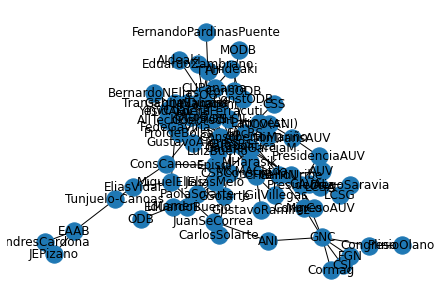

In [ ]:
nx.write_gexf(G1,"Gch1.gexf")
#nx.write_graphml(G,"a.graphml")
nx.draw(G1, with_labels   = True)
communities1 = nx.algorithms.community.asyn_lpa_communities(G1)
print(list(communities1))



In [ ]:
num_nodes1 = G1.number_of_nodes()
num_edges1 = G1.number_of_edges()
sns.set_style(style='darkgrid')

In [ ]:
# — — — — — — — — — let us store the degree centralities for each nodes for a graph in a dictionary
deg_cen1 = {}
graphs=[G1]

for g in graphs:
 
 deg_cen1[g] = nx.degree_centrality(g)
print('deg_cen1')
deg_cen1

#Closeness Centrality
clo_cen1 = {}
for g in graphs:
 clo_cen1[g] = nx.closeness_centrality(g)
print('clo_cen1')
clo_cen1

# Eigen Vector Centrality
eig_cen1 = {}
for g in graphs:
 eig_cen1[g] = nx.eigenvector_centrality(g)
eig_cen1



deg_cen1
clo_cen1


{<networkx.classes.graph.Graph at 0x7fe3d6fd5640>: {'GNC': 0.01448745997673638,
  'CSJ': 0.0024261923904303276,
  'Congreso': 0.0024962067284550484,
  'FGN': 0.0024261923904303276,
  'ANI': 0.0036577191052371456,
  'Presidencia': 0.04790923957745573,
  'MinCo': 0.02516846887132758,
  'Cormag': 0.0024261923904303276,
  'PresidenciaAUV': 0.019307434655992706,
  'AUV': 0.012932452764048606,
  'MarioUribe': 0.010010132105400991,
  'CongresoAUV': 0.0016762440671475576,
  'MinTransAUV': 0.05445383713267863,
  'GabrielGarciaM': 0.21419733681905023,
  'PlinioOlano': 0.00041804768489638576,
  'EliasVidal': 0.006741929991756794,
  'MiguelElias': 0.04026165994096907,
  'LCSA': 0.02435024726464465,
  'GAVAL': 0.04576498390773225,
  'CFC': 0.1416266842447375,
  'JEliasMelo': 0.08647145238498415,
  'NHMN': 0.08789316924747086,
  'LCSG': 0.011742385422828456,
  'JGilVillegas': 0.038436730751938576,
  'GustavoRamirez': 0.02371740782185915,
  'DiegoSaravia': 0.007664326796836064,
  'Odebrecht': 0.44672

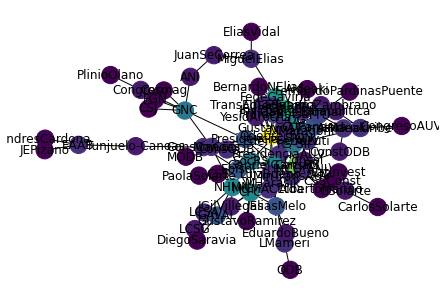

In [ ]:
degree_centrality=nx.degree_centrality(G1)
nx.draw(G1, node_color=[degree_centrality[node] for node in G1.nodes()], cmap='viridis', with_labels   = True)

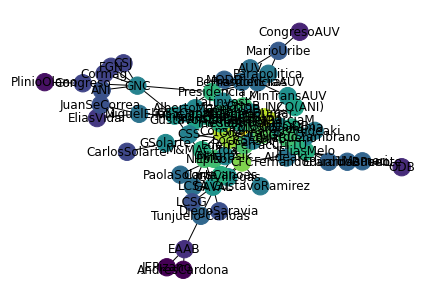

In [ ]:
closeness_centrality=nx.closeness_centrality(G1)
nx.draw(G1, node_color=[closeness_centrality[node] for node in G1.nodes()], cmap='viridis', with_labels   = True)

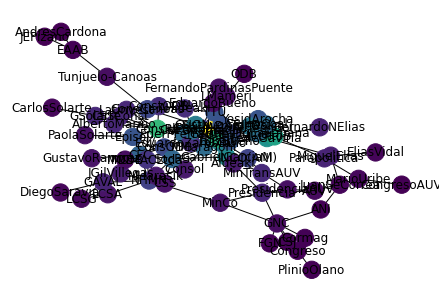

In [ ]:
eigenvector_centrality=nx.eigenvector_centrality(G1)
nx.draw(G1, node_color=[eigenvector_centrality[node] for node in G1.nodes()], cmap='viridis', with_labels   = True)

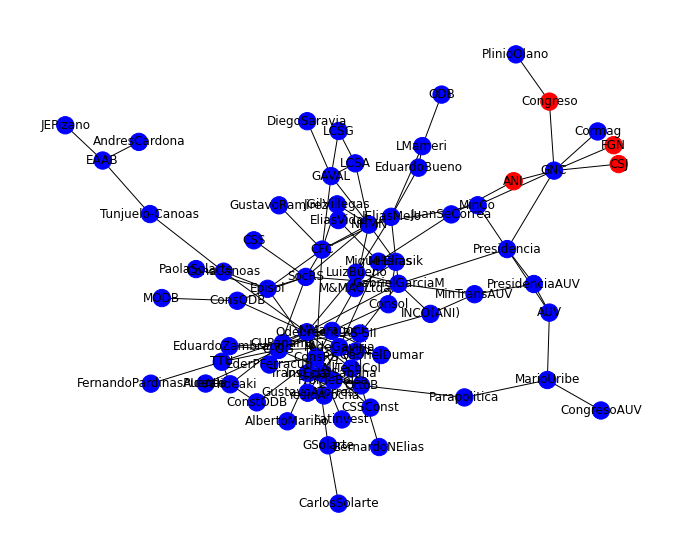

In [ ]:
graph2 = G1
color = []
fig = plt.subplots(1, figsize=(12,10))
for node in graph2:
 if (node == 'CSJ' or node == 'FGN' or node == 'ANI' or node=='Congreso'):
  color.append('red')
 else:
  color.append('blue')
 
nx.draw_spring(graph2,node_color=color,with_labels=True)


In [ ]:
betweenness_centrality = nx.betweenness_centrality(G1)

# Calculate the entropy of the betweenness centrality distribution
betweenness_entropy1 = -np.sum(np.array(list(betweenness_centrality.values())) * np.log2(np.array(list(betweenness_centrality.values()))))

print("Entropy of the betweenness centrality distribution:", betweenness_entropy1)

Entropy of the betweenness centrality distribution: nan


<ipython-input-28-7a223f1f849d>:4: RuntimeWarning: divide by zero encountered in log2
  betweenness_entropy1 = -np.sum(np.array(list(betweenness_centrality.values())) * np.log2(np.array(list(betweenness_centrality.values()))))
<ipython-input-28-7a223f1f849d>:4: RuntimeWarning: invalid value encountered in multiply
  betweenness_entropy1 = -np.sum(np.array(list(betweenness_centrality.values())) * np.log2(np.array(list(betweenness_centrality.values()))))


In [ ]:
def entropy(G):
    degrees = np.array([d for n, d in G.degree()])
    prob = degrees / degrees.sum()
    entropy = -np.sum(prob * np.log2(prob))
    return entropy

In [ ]:
entropy(G1)

5.83955412673783

In [ ]:
#Spectral Clustering

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.csgraph as csgraph

def spectral_clustering(G, k):
    adj_matrix = nx.to_numpy_array(G)
    laplacian = csgraph.laplacian(adj_matrix, normed=True)
    eigen_vals, eigen_vecs = np.linalg.eigh(laplacian)
    eigen_vecs = eigen_vecs[:, np.argsort(eigen_vals)[:k]]
    kmeans = KMeans(n_clusters=k)
    return kmeans.fit_predict(eigen_vecs)

def plot_clusters(G, labels, title):
    pos = nx.spring_layout(G)
    nx.draw(G, pos, with_labels=True)
    nx.draw_networkx_nodes(G, pos, node_color=labels, cmap='viridis', node_size=500)
    plt.title(title)
    plt.show()



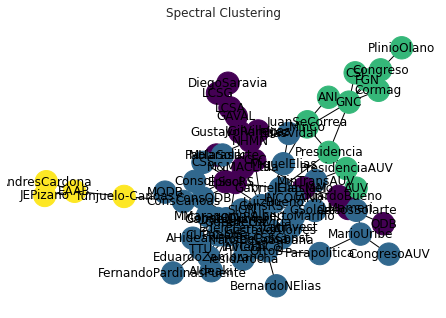

In [ ]:
# Perform spectral clustering
k = 4
labels = spectral_clustering(G1, k)

# Plot the graph clusters
plot_clusters(G1, labels, 'Spectral Clustering')

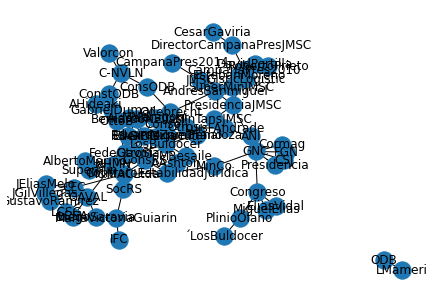

In [ ]:

nx.write_gexf(G2,"Gch2.gexf")
#nx.write_graphml(G,"a.graphml")
nx.draw(G2, with_labels   = True)


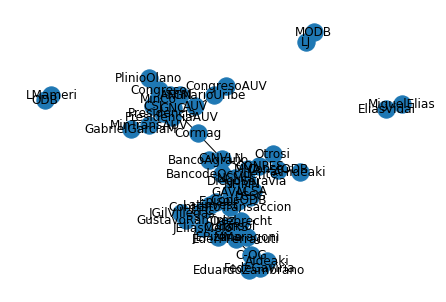

In [ ]:


nx.write_gexf(G3,"Gch3.gexf")
#nx.write_graphml(G,"a.graphml")
nx.draw(G3, with_labels   = True)


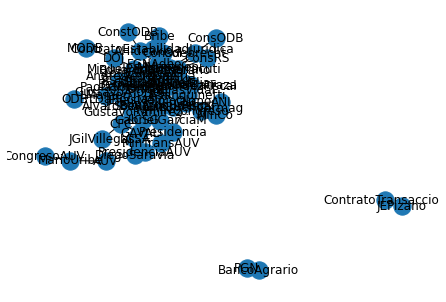

In [ ]:
nx.write_gexf(G4,"Gch4.gexf")
#nx.write_graphml(G,"a.graphml")
nx.draw(G4, with_labels   = True)



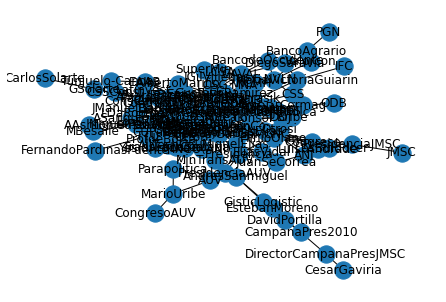

In [ ]:
nx.write_gexf(GALLTIMES,"GALLTIMES.gexf")
#nx.write_graphml(G,"a.graphml")
nx.draw(GALLTIMES, with_labels   = True)


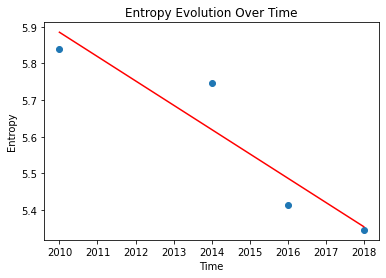

In [ ]:
def entropy(G):
    degrees = np.array([d for n, d in G.degree()])
    prob = degrees / degrees.sum()
    entropy = -np.sum(prob * np.log2(prob))
    return entropy

entropy_1 = entropy(G1)
entropy_2 = entropy(G2)
entropy_3 = entropy(G3)
entropy_4 = entropy(G4)

times = [2010, 2014, 2016, 2018]
entropies = [entropy_1, entropy_2, entropy_3, entropy_4]

times = np.array(times).reshape(-1, 1)
regressor = LinearRegression()
regressor.fit(times, entropies)

entropy_prediction = regressor.predict(times)

plt.scatter(times, entropies)
plt.plot(times, entropy_prediction, color='red')
plt.xlabel('Time')
plt.ylabel('Entropy')
plt.title('Entropy Evolution Over Time')
plt.show()


In [ ]:
nx.draw_spectral(G2, with_labels = True)

TypeError: ignored

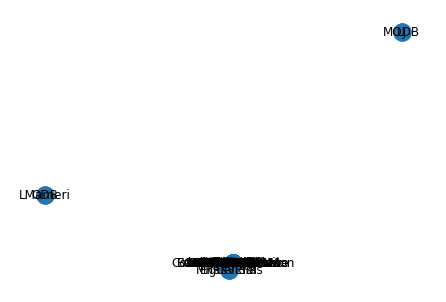

In [ ]:

nx.draw_spectral(G3, with_labels = True)


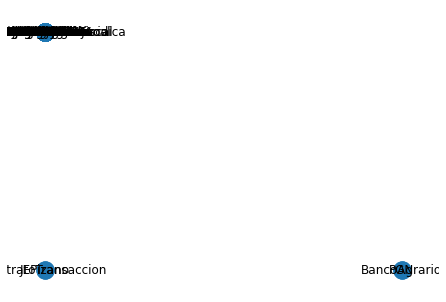

In [ ]:

nx.draw_spectral(G4, with_labels = True)


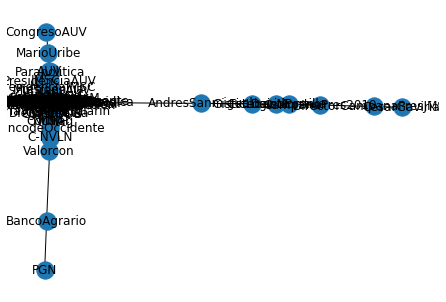

In [ ]:
nx.draw_spectral(GALLTIMES, with_labels = True)

In [ ]:
degrees=g.degree()
degree_values1 = sorted([val for (node, val) in g.degree()])

In [ ]:
degree_values1

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 4,
 4,
 4,
 4,
 4,
 4,
 4,
 4,
 5,
 5,
 5,
 6,
 6,
 6,
 6,
 7,
 8,
 8,
 9,
 10,
 13]

In [ ]:
degree_values=sorted(set(dict(degrees).values()))

In [ ]:
histogram=[list(dict(degrees).values()).count(i)/float(nx.number_of_nodes(g)) for i in degree_values]

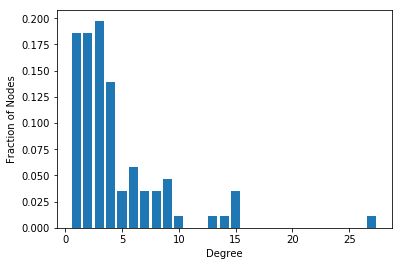

'This can be usefull to prove power law distribution - rich get richer phenomenon\nCould be compared to barabasi_albert_graph(n,m) which returns a ntwk with n nodes. \nEach node ataches to m existing nodes according to Preferential Attachement Model - Perfect Power law distribution\nsmall world degree distribution is never pawer law, is kind of Gaussian and Power lawe models are naturally found in social networks\n'

In [ ]:
plt.bar(degree_values,histogram)
plt.xlabel('Degree')
plt.ylabel('Fraction of Nodes')
plt.show()
"""This can be usefull to prove power law distribution - rich get richer phenomenon
Could be compared to barabasi_albert_graph(n,m) which returns a ntwk with n nodes. 
Each node ataches to m existing nodes according to Preferential Attachement Model - Perfect Power law distribution
small world degree distribution is never power law, is kind of Gaussian and Power law models are naturally found in social networks
"""

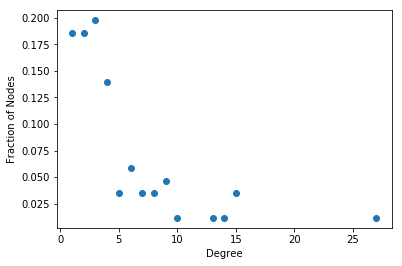

In [ ]:
plt.plot(degree_values,histogram, 'o')
plt.xlabel('Degree')
plt.ylabel('Fraction of Nodes')
#plt.xscale('log')
#plt.yscale('log')
plt.show()

In [ ]:
L = list(nx.jaccard_coefficient(g))

In [ ]:
L.sort(key=operator.itemgetter(2),reverse = True)

In [ ]:
LLCSA=[None]

In [ ]:
for i in L:
    if 'LCSA' in i: 
        LLCSA.append(i)
        print (i)

('LCSA', 'SuperMin', 0.3333333333333333)
('LCSA', 'CFC', 0.2857142857142857)
('DiegoSaravia', 'LCSA', 0.25)
('MNA', 'LCSA', 0.16666666666666666)
('ConsRS', 'LCSA', 0.09090909090909091)
('LCSA', 'SocRS', 0.08333333333333333)
('FGN', 'LCSA', 0.07142857142857142)
('LCSA', 'C-OG', 0.06666666666666667)
('EstebanMoreno', 'LCSA', 0.0)
('MiguelPenaloza', 'LCSA', 0.0)
('MariaVictoriaGuiarin', 'LCSA', 0.0)
('OttoB', 'LCSA', 0.0)
('MODB', 'LCSA', 0.0)
('AUV', 'LCSA', 0.0)
('PlinioOlano', 'LCSA', 0.0)
('FernandoPardinasPuente', 'LCSA', 0.0)
('GNC', 'LCSA', 0.0)
('CesarGaviria', 'LCSA', 0.0)
('CampanaPresJMSC', 'LCSA', 0.0)
('JMSC', 'LCSA', 0.0)
('Consol', 'LCSA', 0.0)
('PresidenciaJMSC', 'LCSA', 0.0)
('AHideaki', 'LCSA', 0.0)
('RobertoPrieto', 'LCSA', 0.0)
('AndresSanmiguel', 'LCSA', 0.0)
('ANI', 'LCSA', 0.0)
('MinTansJMSC', 'LCSA', 0.0)
('LMameri', 'LCSA', 0.0)
('MBesaile', 'LCSA', 0.0)
('EliasVidal', 'LCSA', 0.0)
('AAshton', 'LCSA', 0.0)
('CSSConst', 'LCSA', 0.0)
('LJ', 'LCSA', 0.0)
('GisticLogi

In [ ]:
LLCSA

[None,
 ('LCSA', 'SuperMin', 0.3333333333333333),
 ('LCSA', 'CFC', 0.2857142857142857),
 ('DiegoSaravia', 'LCSA', 0.25),
 ('MNA', 'LCSA', 0.16666666666666666),
 ('ConsRS', 'LCSA', 0.09090909090909091),
 ('LCSA', 'SocRS', 0.08333333333333333),
 ('FGN', 'LCSA', 0.07142857142857142),
 ('LCSA', 'C-OG', 0.06666666666666667),
 ('EstebanMoreno', 'LCSA', 0.0),
 ('MiguelPenaloza', 'LCSA', 0.0),
 ('MariaVictoriaGuiarin', 'LCSA', 0.0),
 ('OttoB', 'LCSA', 0.0),
 ('MODB', 'LCSA', 0.0),
 ('AUV', 'LCSA', 0.0),
 ('PlinioOlano', 'LCSA', 0.0),
 ('FernandoPardinasPuente', 'LCSA', 0.0),
 ('GNC', 'LCSA', 0.0),
 ('CesarGaviria', 'LCSA', 0.0),
 ('CampanaPresJMSC', 'LCSA', 0.0),
 ('JMSC', 'LCSA', 0.0),
 ('Consol', 'LCSA', 0.0),
 ('PresidenciaJMSC', 'LCSA', 0.0),
 ('AHideaki', 'LCSA', 0.0),
 ('RobertoPrieto', 'LCSA', 0.0),
 ('AndresSanmiguel', 'LCSA', 0.0),
 ('ANI', 'LCSA', 0.0),
 ('MinTansJMSC', 'LCSA', 0.0),
 ('LMameri', 'LCSA', 0.0),
 ('MBesaile', 'LCSA', 0.0),
 ('EliasVidal', 'LCSA', 0.0),
 ('AAshton', 'LC

ValueError: True is not in list

In [ ]:
print(L)
#Number of common neighbors normalized by the total
#number of neighbors

In [ ]:
LRA = list(nx.resource_allocation_index(g))

In [ ]:
LRA.sort(key=operator.itemgetter(2), reverse = True)

In [ ]:
print(LRA)
#Fraction of a ”resource” that a node can send to
#another through their common neighbors

In [ ]:
LPA = list(nx.preferential_attachment(g))

In [ ]:
LPA.sort(key=operator.itemgetter(2), reverse = True)

In [ ]:
print(LPA)

In [ ]:
histogram=[list(degree_values2()).count(i)/float(nx.number_of_nodes(g)) for i in degree_values2]

In [ ]:
N, K = cam_net.order(), cam_net.size()
avg_deg = float(K) / N

print ("Nodes: ", N)
print ("Edges: ", K)
print ("Average degree: ", avg_deg)
print ("SCC: ", nx.number_strongly_connected_components(cam_net))
print ("WCC: ", nx.number_weakly_connected_components(cam_net))